# Разведочный анализ данных

## 1. Паспорт данных

Источник — подготовленные рыночные бары Massive из `../../data/processed`. Одна строка описывает OHLCV-бар одного инструмента: цены открытия, максимума, минимума и закрытия, объём и дополнительные поля.

Состав выборки и период ниже вычисляются по **локально доступным файлам**, а названия и группы инструментов берутся из `../../config/instruments.yaml`. Плановый период проекта: 15.11.2021–30.09.2026; фактические границы определяются отдельно. Это паспорт данных, проверки качества будут следующим разделом.

In [12]:
from pathlib import Path

import pandas as pd
import pyarrow.parquet as pq
import yaml
from IPython.display import display, Markdown

# Поддерживаем запуск как из корня проекта, так и из notebooks/.
project_root = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "config/instruments.yaml").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Не найден корень проекта с config/instruments.yaml")

with (project_root / "config/instruments.yaml").open(encoding="utf-8") as f:
    instruments_config = yaml.safe_load(f)

instrument_info = {}
for asset, groups in (("stocks", instruments_config["stocks"]),
                      ("futures", instruments_config["futures"])):
    for group, instruments in groups.items():
        if group == "blue_chips":  # Это повторный список уже включённых акций.
            continue
        for instrument in instruments:
            instrument_info[(asset, instrument["ticker"])] = {
                "group": group,
                "name": instrument.get("name_ru", instrument["name"]),
            }

asset_directories = {
    "stocks": project_root / "data/processed/stocks",
    "futures": project_root / "data/processed/futures_continuous",
}
file_records, schema_records = [], []
for asset, directory in asset_directories.items():
    paths = sorted(directory.glob("*.parquet"))
    if not paths:
        raise FileNotFoundError(f"Нет parquet-файлов: {directory}")
    for path in paths:
        ticker, timeframe = path.stem.rsplit("_", 1)
        parquet = pq.ParquetFile(path)
        times = parquet.read(columns=["time"]).column("time").to_pandas()
        info = instrument_info.get((asset, ticker), {"group": "unknown", "name": ticker})
        file_records.append({
            "asset": asset, "ticker": ticker, "timeframe": timeframe, **info,
            "rows": parquet.metadata.num_rows,
            "columns": len(parquet.schema_arrow),
            "start_utc": times.min(), "end_utc": times.max(),
            "size_mib": path.stat().st_size / 1024**2,
        })
        for field in parquet.schema_arrow:
            schema_records.append({
                "asset": asset, "timeframe": timeframe,
                "field": field.name, "dtype": str(field.type),
            })

file_passport = pd.DataFrame(file_records)
field_passport = pd.DataFrame(schema_records).drop_duplicates()

In [13]:
file_passport

,asset,ticker,timeframe,group,name,rows,columns,start_utc,end_utc,size_mib
0,stocks,AEP,15min,utilities,"American Electric Power Company, Inc.",38518,22,2021-11-15 13:00:00+00:00,2026-09-30 23:00:00+00:00,3.065428
1,stocks,AEP,1day,utilities,"American Electric Power Company, Inc.",1223,23,2021-11-15 05:00:00+00:00,2026-09-30 04:00:00+00:00,0.150429
2,stocks,AEP,1hour,utilities,"American Electric Power Company, Inc.",12287,22,2021-11-15 13:00:00+00:00,2026-09-30 23:00:00+00:00,1.152280
3,stocks,AEP,4hour,utilities,"American Electric Power Company, Inc.",4177,22,2021-11-15 13:00:00+00:00,2026-09-30 20:00:00+00:00,0.440876
4,stocks,AEP,5min,utilities,"American Electric Power Company, Inc.",103483,22,2021-11-15 13:00:00+00:00,2026-09-30 23:00:00+00:00,6.880215
...,...,...,...,...,...,...,...,...,...,...
166,futures,ZN,1hour,bonds,10-летние Treasury Notes,28818,10,2021-11-14 23:00:00+00:00,2026-09-30 20:00:00+00:00,0.872583
167,futures,ZN,4hour,bonds,10-летние Treasury Notes,8778,10,2021-11-14 20:00:00+00:00,2026-09-30 20:00:00+00:00,0.355552
168,futures,ZT,15min,bonds,2-летние Treasury Notes,115118,10,2021-11-14 23:00:00+00:00,2026-09-30 20:45:00+00:00,2.523554
169,futures,ZT,1hour,bonds,2-летние Treasury Notes,28818,10,2021-11-14 23:00:00+00:00,2026-09-30 20:00:00+00:00,0.837697


### 1.1. Объём и временное покрытие

Размер указан в MiB для сжатых файлов на диске, а не для DataFrame в оперативной памяти. Строки разных таймфреймов описывают одни и те же торги с разной агрегацией — складывать их как независимые наблюдения нельзя. Границы в UTC относятся к началу бара; у фьючерсов первая сессия может начинаться вечером предыдущего календарного дня.

In [15]:
timeframe_order = {"5min": 0, "15min": 1, "1hour": 2, "4hour": 3, "1day": 4}
summary_passport = (
    file_passport.groupby(["asset", "timeframe"], as_index=False)
    .agg(instruments=("ticker", "nunique"), files=("ticker", "size"),
         rows=("rows", "sum"), min_columns=("columns", "min"),
         max_columns=("columns", "max"), start_utc=("start_utc", "min"),
         end_utc=("end_utc", "max"), size_mib=("size_mib", "sum"))
    .assign(_order=lambda df: df["timeframe"].map(timeframe_order))
    .sort_values(["asset", "_order"]).drop(columns="_order")
    .reset_index(drop=True)
)
display(summary_passport.round({"size_mib": 2}))

display(Markdown(
    f"Доступно **{len(file_passport):,} файлов**, "
    f"**{file_passport.loc[file_passport.asset.eq('stocks'), 'ticker'].nunique()} акций** и "
    f"**{file_passport.loc[file_passport.asset.eq('futures'), 'ticker'].nunique()} фьючерсов**. "
    f"Общий размер файлов: **{file_passport.size_mib.sum():,.2f} MiB**."
))

,asset,timeframe,instruments,files,rows,min_columns,max_columns,start_utc,end_utc,size_mib
0,futures,15min,7,7,791220,10,10,2021-11-14 23:00:00+00:00,2026-09-30 20:45:00+00:00,17.70
1,futures,1hour,7,7,200919,10,10,2021-11-14 23:00:00+00:00,2026-09-30 20:00:00+00:00,5.94
2,futures,4hour,7,7,61317,10,10,2021-11-14 20:00:00+00:00,2026-09-30 20:00:00+00:00,2.50
3,stocks,5min,30,30,3948613,22,22,2021-11-15 09:00:00+00:00,2026-09-30 23:55:00+00:00,275.93
4,stocks,15min,30,30,1529619,22,22,2021-11-15 09:00:00+00:00,2026-09-30 23:45:00+00:00,123.14
5,stocks,1hour,30,30,459742,22,22,2021-11-15 09:00:00+00:00,2026-09-30 23:00:00+00:00,43.08
6,stocks,4hour,30,30,136111,22,22,2021-11-15 09:00:00+00:00,2026-09-30 20:00:00+00:00,14.41
7,stocks,1day,30,30,36690,23,23,2021-11-15 05:00:00+00:00,2026-09-30 04:00:00+00:00,4.49


Доступно **171 файлов**, **30 акций** и **7 фьючерсов**. Общий размер файлов: **487.19 MiB**.

### 1.2. Состав выборки

Для каждой группы показаны доступные инструменты и таймфреймы. Пара `asset` + `ticker` определяет инструмент: одинаковые тикеры могут встречаться у акций и фьючерсов. Подробная таблица ниже содержит одну строку на файл; она позволяет увидеть различия в покрытии между инструментами.

In [16]:
group_passport = (
    file_passport.groupby(["asset", "group"], as_index=False)
    .agg(instruments=("ticker", "nunique"),
         tickers=("ticker", lambda s: ", ".join(sorted(set(s)))),
         timeframes=("timeframe", lambda s: ", ".join(
             sorted(set(s), key=lambda x: timeframe_order.get(x, 99)))))
)
display(group_passport)

# Отдельная таблица имён без повторений по таймфреймам.
display(file_passport[["asset", "group", "ticker", "name"]]
        .drop_duplicates().sort_values(["asset", "group", "ticker"])
        .reset_index(drop=True))

,asset,group,instruments,tickers,timeframes
0,futures,bonds,7,"TN, UB, Z3N, ZB, ZF, ZN, ZT","15min, 1hour, 4hour"
1,stocks,communication_services,10,"APP, CMCSA, DIS, GOOGL, META, NFLX, T, TMUS, T...","5min, 15min, 1hour, 4hour, 1day"
2,stocks,financials,10,"AXP, BAC, BRK.B, C, GS, JPM, MA, MS, V, WFC","5min, 15min, 1hour, 4hour, 1day"
3,stocks,utilities,10,"AEP, D, DUK, ETR, EXC, NEE, SO, SRE, VST, XEL","5min, 15min, 1hour, 4hour, 1day"


,asset,group,ticker,name
0,futures,bonds,TN,Ultra 10-летние Treasury Notes
1,futures,bonds,UB,Ultra Treasury Bonds
2,futures,bonds,Z3N,3-летние Treasury Notes
3,futures,bonds,ZB,30-летние Treasury Bonds
4,futures,bonds,ZF,5-летние Treasury Notes
5,futures,bonds,ZN,10-летние Treasury Notes
6,futures,bonds,ZT,2-летние Treasury Notes
7,stocks,communication_services,APP,Applovin Corporation Class A Common Stock
8,stocks,communication_services,CMCSA,Comcast Corp
9,stocks,communication_services,DIS,The Walt Disney Company


### 1.3. Словарь полей и устройство рядов

**Акции.** `open/high/low/close` — исходные цены; `split_adj_*` учитывают сплиты, `adj_*` — сплиты и дивиденды. Для анализа доходностей используется `adj_close`. Объём измеряется в акциях.

**Фьючерсы.** Непрерывные ряды склеены из контрактов методом ratio back-adjust. OHLC уже скорректированы; исходная цена контракта равна скорректированной цене, делённой на `factor`. Объём измеряется в контрактах. Изменение цены облигационного фьючерса не является изменением доходности облигации.

**Время и идентификаторы.** `time` хранится в UTC. Основная сессия акций определяется по Нью-Йорку; переходы на летнее время нужно учитывать. `in_session` отмечает пересечение бара с основной сессией, поэтому часовые и 4-часовые бары могут захватывать и внесессионные торги. У одного фьючерса допустимы одинаковые `time` с разными `session_end_date`; ключ строки внутри инструмента и таймфрейма — эта пара. В файлах фьючерсов код инструмента содержится в имени файла, а `contract` обозначает конкретный контракт: при последующем объединении нужно явно добавить `ticker`.

In [4]:
field_descriptions = {
    "time": "Время начала бара, UTC",
    "ticker": "Текущий унифицированный тикер акции",
    "source_ticker": "Тикер источника на дату бара, включая прежние названия",
    "open": "Цена открытия бара", "high": "Максимальная цена бара",
    "low": "Минимальная цена бара", "close": "Цена закрытия бара",
    "volume": "Объём: акции для stocks, контракты для futures",
    "split_adj_volume": "Объём акций с корректировкой на сплиты",
    "vwap": "Средневзвешенная по объёму цена из исходных баров",
    "trades": "Число сделок в баре акции",
    "transactions": "Число транзакций в баре фьючерса",
    "split_factor": "Множитель корректировки цены акции на сплиты",
    "dividend_factor": "Множитель корректировки цены акции на дивиденды",
    "in_session": "Бар пересекает основную торговую сессию акций",
    "day_bar_fixed": "Дневной бар акции восстановлен из 5-минутных баров",
    "session_end_date": "Торговая дата сессии фьючерса",
    "contract": "Контракт, из которого взят бар непрерывного ряда",
    "factor": "Множитель ratio back-adjust для цены фьючерса",
}
for price in ["open", "high", "low", "close"]:
    field_descriptions[f"split_adj_{price}"] = f"{price}: цена акции с учётом сплитов"
    field_descriptions[f"adj_{price}"] = f"{price}: цена акции с учётом сплитов и дивидендов"

field_dictionary = (
    field_passport.groupby(["asset", "field", "dtype"], as_index=False)
    .agg(timeframes=("timeframe", lambda s: ", ".join(
        sorted(set(s), key=lambda x: timeframe_order.get(x, 99)))))
)
field_dictionary["description"] = field_dictionary["field"].map(field_descriptions).fillna(
    "Поле отсутствует в словаре — требуется уточнение")
with pd.option_context("display.max_rows", len(field_dictionary), "display.max_colwidth", 95):
    display(field_dictionary)

,asset,field,dtype,timeframes,description
0,futures,close,double,"15min, 1hour, 4hour",Цена закрытия бара
1,futures,contract,string,"15min, 1hour, 4hour","Контракт, из которого взят бар непрерывного ряда"
2,futures,factor,double,"15min, 1hour, 4hour",Множитель ratio back-adjust для цены фьючерса
3,futures,high,double,"15min, 1hour, 4hour",Максимальная цена бара
4,futures,low,double,"15min, 1hour, 4hour",Минимальная цена бара
5,futures,open,double,"15min, 1hour, 4hour",Цена открытия бара
6,futures,session_end_date,string,"15min, 1hour, 4hour",Торговая дата сессии фьючерса
7,futures,time,"timestamp[ns, tz=UTC]","15min, 1hour, 4hour","Время начала бара, UTC"
8,futures,transactions,int64,"15min, 1hour, 4hour",Число транзакций в баре фьючерса
9,futures,volume,int64,"15min, 1hour, 4hour","Объём: акции для stocks, контракты для futures"


### Ограничения выборки

- Это доступная локальная часть командного датасета, а не весь рынок США. Состав групп задан в конфигурации проекта.
- Акции отобраны по составу крупных компаний на конец периода с требованием полной истории. Возможны смещения отбора и выживших компаний; выводы нельзя автоматически переносить на исторический состав S&P 500.
- Покрытие от первой до последней отметки времени не гарантирует отсутствия пропусков внутри ряда. Наличие файлов и схема полей также не подтверждают качество значений.
- Корректировки акций и фьючерсов используют последующие корпоративные события и склейки. При моделировании нужно отдельно проверить доступность признаков на момент прогноза.
- 4-часовые интервалы акций и фьючерсов зимой имеют разные границы. Межрыночные сравнения требуют согласования времени и торговых сессий.

Далее: проверка пропусков, ключей строк и корректности OHLCV.

In [2]:
import numpy as np
import pandas as pd

from glob import glob

In [4]:
def read_files_by_pattern(filenames: str):
    ls_dfs = []
    for path in glob(filenames):
        df = pd.read_parquet(path)
        ls_dfs.append(df)

    return pd.concat(ls_dfs, axis=0, ignore_index=True)

In [5]:
stocks_5_min_path = "../data/processed/stocks/*_5min.parquet"
stocks_15_min_path = "../data/processed/stocks/*_15min.parquet"
stocks_1_hour_path = "../data/processed/stocks/*_1hour.parquet"
stocks_4_hour_path = "../data/processed/stocks/*_4hour.parquet"

futures_15_min_path = "../data/processed/futures_continuous/*_15min.parquet"
futures_1_hour_path = "../data/processed/futures_continuous/*_1hour.parquet"
futures_4_hour_path = "../data/processed/futures_continuous/*_4hour.parquet"

In [7]:
stocks_5_min = read_files_by_pattern(stocks_5_min_path)
stocks_15_min = read_files_by_pattern(stocks_15_min_path)
stocks_1_hour = read_files_by_pattern(stocks_1_hour_path)
stocks_4_hour = read_files_by_pattern(stocks_4_hour_path)

futures_15_min = read_files_by_pattern(futures_15_min_path)
futures_1_hour = read_files_by_pattern(futures_1_hour_path)
futures_4_hour = read_files_by_pattern(futures_4_hour_path)


### Смотрим Nones

In [17]:
# None, NaN, pd.NA и NaT считаются пропусками; нули и пустые строки — нет.
# Анализируем семь загруженных выше выборок отдельно по таймфреймам.
from IPython.display import display, Markdown

samples = {
    "stocks_5min": stocks_5_min,
    "stocks_15min": stocks_15_min,
    "stocks_1hour": stocks_1_hour,
    "stocks_4hour": stocks_4_hour,
    "futures_15min": futures_15_min,
    "futures_1hour": futures_1_hour,
    "futures_4hour": futures_4_hour,
}
null_summary, null_columns = [], []
for sample_name, frame in samples.items():
    missing = frame.isna()
    by_column = missing.sum()
    affected_rows = int(missing.any(axis=1).sum())
    total_missing = int(by_column.sum())
    null_summary.append({
        "Выборка": sample_name,
        "Строк": len(frame),
        "Столбцов": frame.shape[1],
        "Пропусков": total_missing,
        "Пропусков, % ячеек": 100 * total_missing / frame.size if frame.size else float("nan"),
        "Строк с пропусками": affected_rows,
        "Строк с пропусками, %": 100 * affected_rows / len(frame) if len(frame) else float("nan"),
        "Столбцов с пропусками": int(by_column.gt(0).sum()),
    })
    for column, count in by_column[by_column.gt(0)].items():
        null_columns.append({
            "Выборка": sample_name, "Столбец": column,
            "Тип": str(frame[column].dtype), "Пропусков": int(count),
            "Пропусков, % строк": 100 * count / len(frame),
        })
    del missing  # Не держим булевы маски всех выборок в памяти.

null_summary = pd.DataFrame(null_summary)
null_columns = pd.DataFrame(null_columns, columns=[
    "Выборка", "Столбец", "Тип", "Пропусков", "Пропусков, % строк",
])
display(Markdown("**Сводка пропусков по выборкам**"))
with pd.option_context("display.max_columns", None, "display.float_format", "{:.6f}".format):
    display(null_summary)

if null_columns.empty:
    display(Markdown(
        "**Вывод:** во всех семи загруженных выборках пропуски значений отсутствуют. "
        "Удаление строк и заполнение значений по этому критерию не требуются."
    ))
else:
    display(Markdown("**Столбцы с пропусками** (доля рассчитана от числа строк своей выборки)"))
    with pd.option_context("display.max_rows", len(null_columns),
                           "display.float_format", "{:.6f}".format):
        display(null_columns.sort_values(["Выборка", "Пропусков"], ascending=[True, False])
                .reset_index(drop=True))
    display(Markdown(
        f"**Вывод:** пропуски найдены в {int(null_summary['Пропусков'].gt(0).sum())} "
        "из семи выборок. Перед заполнением или удалением нужно выяснить их причины "
        "в перечисленных столбцах."
    ))
display(Markdown(
    "Проверка относится к значениям в существующих строках. "
    "Отсутствующие временные бары, бесконечности и текстовые маркеры вроде строки `None` "
    "требуют отдельных проверок. Дневные акции в эти семь выборок не входят."
))


**Сводка пропусков по выборкам**

,Выборка,Строк,Столбцов,Пропусков,"Пропусков, % ячеек",Строк с пропусками,"Строк с пропусками, %",Столбцов с пропусками
0,stocks_5min,3948613,22,0,0.000000,0,0.000000,0
1,stocks_15min,1529619,22,0,0.000000,0,0.000000,0
2,stocks_1hour,459742,22,0,0.000000,0,0.000000,0
3,stocks_4hour,136111,22,0,0.000000,0,0.000000,0
4,futures_15min,791220,10,0,0.000000,0,0.000000,0
5,futures_1hour,200919,10,0,0.000000,0,0.000000,0
6,futures_4hour,61317,10,0,0.000000,0,0.000000,0


**Вывод:** во всех семи загруженных выборках пропуски значений отсутствуют. Удаление строк и заполнение значений по этому критерию не требуются.

Проверка относится к значениям в существующих строках. Отсутствующие временные бары, бесконечности и текстовые маркеры вроде строки `None` требуют отдельных проверок. Дневные акции в эти семь выборок не входят.

In [18]:
# Отсутствующие бары: календарная сетка минус фактически доступные отметки времени.
import pandas_market_calendars as mcal
from IPython.display import display, Markdown

bar_frequencies = {"5min": "5min", "15min": "15min", "1hour": "1h", "4hour": "4h"}
# Период всего исследования, а не границы отдельного инструмента:
# так обнаруживаются и полностью отсутствующие сессии, включая края периода.
coverage_start, coverage_end = "2021-11-15", "2026-09-30"
bar_schedules = {
    "stocks": mcal.get_calendar("NYSE").schedule(coverage_start, coverage_end),
    "futures": mcal.get_calendar("CME_Bond").schedule(coverage_start, coverage_end),
}
expected_grids = {}
for asset, schedule in bar_schedules.items():
    for timeframe, frequency in bar_frequencies.items():
        if asset == "futures" and timeframe == "5min":
            continue
        pieces = []
        for session in schedule.itertuples():
            opening, closing = session.market_open, session.market_close
            # Акции агрегируются по локальному времени Нью-Йорка, фьючерсы — по UTC.
            if asset == "stocks":
                opening = opening.tz_convert("America/New_York")
                closing = closing.tz_convert("America/New_York")
            # Включаем каждый бар, пересекающий сессию: часовой бар начинается в 09:00,
            # 4-часовой — в 08:00 по Нью-Йорку. Бар в момент закрытия уже не входит.
            pieces.append(pd.date_range(opening.floor(frequency),
                                        (closing - pd.Timedelta("1ns")).floor(frequency),
                                        freq=frequency).tz_convert("UTC"))
        expected_grids[(asset, timeframe)] = pieces[0].append(pieces[1:]).unique().sort_values()

coverage_records, missing_parts = [], []
# Читаем только time из каждого файла: имя файла сохраняет идентичность фьючерса,
# которую теряет объединённый DataFrame без столбца ticker.
for asset, directory in asset_directories.items():
    for path in sorted(directory.glob("*.parquet")):
        ticker, timeframe = path.stem.rsplit("_", 1)
        if (asset, timeframe) not in expected_grids:
            continue  # Дневные акции не входят в текущие внутридневные выборки.
        expected = expected_grids[(asset, timeframe)]
        actual = pd.DatetimeIndex(pd.read_parquet(path, columns=["time"])["time"]).dropna().unique()
        missing = expected.difference(actual)
        outside = actual.difference(expected)
        coverage_records.append({
            "asset": asset, "ticker": ticker, "timeframe": timeframe,
            "expected_bars": len(expected), "present_bars": len(expected) - len(missing),
            "missing_bars": len(missing), "missing_pct": 100 * len(missing) / len(expected),
            "outside_grid": len(outside),
        })
        if len(missing):
            missing_parts.append(pd.DataFrame({
                "asset": asset, "ticker": ticker, "timeframe": timeframe, "time_utc": missing,
            }))

bar_coverage = pd.DataFrame(coverage_records)
missing_bars = (pd.concat(missing_parts, ignore_index=True) if missing_parts else
                pd.DataFrame(columns=["asset", "ticker", "timeframe", "time_utc"]))
bar_coverage_summary = (
    bar_coverage.groupby(["asset", "timeframe"], as_index=False)
    .agg(instruments=("ticker", "nunique"), expected_bars=("expected_bars", "sum"),
         present_bars=("present_bars", "sum"), missing_bars=("missing_bars", "sum"),
         instruments_with_gaps=("missing_bars", lambda s: int(s.gt(0).sum())),
         outside_grid=("outside_grid", "sum"))
    .assign(missing_pct=lambda df: 100 * df.missing_bars / df.expected_bars)
)
display(Markdown("**Отсутствующие внутридневные бары по торговым календарям**"))
with pd.option_context("display.max_columns", None, "display.float_format", "{:.4f}".format):
    display(bar_coverage_summary)
    if not missing_bars.empty:
        display(Markdown("**20 сочетаний инструмент / таймфрейм с наибольшей долей отсутствующих баров**"))
        display(bar_coverage.query("missing_bars > 0")
                .sort_values("missing_pct", ascending=False).head(20).reset_index(drop=True))
        display(Markdown("**Примеры отсутствующих баров: до трёх на класс актива и таймфрейм**"))
        display(missing_bars.sort_values(["asset", "timeframe", "time_utc", "ticker"])
                .groupby(["asset", "timeframe"], sort=False).head(3).reset_index(drop=True))
    else:
        display(Markdown("Отсутствующих баров относительно выбранных календарей не найдено."))
display(Markdown(
    "**Интерпретация.** `missing_pct` — доля отсутствующих отметок от ожидаемой сетки, "
    "`outside_grid` — число фактических отметок вне неё. У акций это преимущественно "
    "расширенные торги, которые здесь не проверяются. Для часовых и 4-часовых акций "
    "проверяется наличие баров, пересекающих основную сессию. "
    "У фьючерсов проверяется наличие временного окна без привязки к `session_end_date`: "
    "части одного окна на границе сессий не считаются отдельными ожидаемыми барами. "
    "Календарь CME может расходиться с праздничными сессиями и их разметкой Massive, "
    "поэтому расхождения по фьючерсам — кандидаты на проверку. "
    "Отсутствие бара также может означать отсутствие сделок, а не ошибку загрузки; "
    "автоматически заполнять такие интервалы нельзя. Полные результаты доступны "
    "в `bar_coverage` и `missing_bars`."
))


/var/folders/xn/pqbclf8n5hg5j3p8p8_nv_p00000gp/T/ipykernel_43447/2797783615.py:28: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  (closing - pd.Timedelta("1ns")).floor(frequency),


**Отсутствующие внутридневные бары по торговым календарям**

,asset,timeframe,instruments,expected_bars,present_bars,missing_bars,instruments_with_gaps,outside_grid,missing_pct
0,futures,15min,7,807009,790685,16324,7,535,2.0228
1,futures,1hour,7,201789,200766,1023,7,153,0.5070
2,futures,4hour,7,54649,54581,68,7,35,0.1244
3,stocks,15min,30,950340,950340,0,0,579279,0.0000
4,stocks,1hour,30,255930,255930,0,0,203812,0.0000
5,stocks,4hour,30,73380,73380,0,0,62731,0.0000
6,stocks,5min,30,2851020,2850993,27,5,1097620,0.0009


**20 сочетаний инструмент / таймфрейм с наибольшей долей отсутствующих баров**

,asset,ticker,timeframe,expected_bars,present_bars,missing_bars,missing_pct,outside_grid
0,futures,Z3N,15min,115287,100079,15208,13.1914,61
1,futures,Z3N,1hour,28827,27990,837,2.9035,21
2,futures,Z3N,4hour,7807,7757,50,0.6405,5
3,futures,ZT,15min,115287,115039,248,0.2151,79
4,futures,TN,15min,115287,115096,191,0.1657,79
5,futures,UB,15min,115287,115098,189,0.1639,79
6,futures,ZB,15min,115287,115117,170,0.1475,79
7,futures,ZF,15min,115287,115118,169,0.1466,79
8,futures,ZN,15min,115287,115138,149,0.1292,79
9,futures,TN,1hour,28827,28796,31,0.1075,22


**Примеры отсутствующих баров: до трёх на класс актива и таймфрейм**

,asset,ticker,timeframe,time_utc
0,futures,Z3N,15min,2021-11-14 23:15:00+00:00
1,futures,Z3N,15min,2021-11-14 23:45:00+00:00
2,futures,Z3N,15min,2021-11-15 02:30:00+00:00
3,futures,Z3N,1hour,2021-11-18 23:00:00+00:00
4,futures,Z3N,1hour,2021-11-21 23:00:00+00:00
5,futures,Z3N,1hour,2021-11-23 00:00:00+00:00
6,futures,Z3N,4hour,2021-11-21 20:00:00+00:00
7,futures,Z3N,4hour,2021-11-25 00:00:00+00:00
8,futures,Z3N,4hour,2021-11-25 04:00:00+00:00
9,stocks,ETR,5min,2021-12-28 17:35:00+00:00


**Интерпретация.** `missing_pct` — доля отсутствующих отметок от ожидаемой сетки, `outside_grid` — число фактических отметок вне неё. У акций это преимущественно расширенные торги, которые здесь не проверяются. Для часовых и 4-часовых акций проверяется наличие баров, пересекающих основную сессию. У фьючерсов проверяется наличие временного окна без привязки к `session_end_date`: части одного окна на границе сессий не считаются отдельными ожидаемыми барами. Календарь CME может расходиться с праздничными сессиями и их разметкой Massive, поэтому расхождения по фьючерсам — кандидаты на проверку. Отсутствие бара также может означать отсутствие сделок, а не ошибку загрузки; автоматически заполнять такие интервалы нельзя. Полные результаты доступны в `bar_coverage` и `missing_bars`.

## 2. Распределения и календарные особенности доходностей акций

Анализируем 30 акций, **15-минутные бары только основной сессии NYSE**, время Нью-Йорка, с учётом праздников и коротких дней. Фьючерсы в этот раздел не входят.

Доходность окна: $r_{t,n}=\ln(C_t^{adj}/O_{t-n+1}^{adj})$, где всё окно находится в одной сессии и содержит ровно `n` последовательных баров. Горизонты: 1, 4 и 16 баров (15 минут, час и четыре часа). Они включают движение первого бара сессии и исключают ночные изменения. Окна при `n > 1` перекрываются; наблюдения зависимы.

Для дней недели и месяцев используем одну доходность **от открытия до закрытия основной сессии** на инструмент и день. Это не полная дневная доходность владения акцией: ночное движение исключено. Месяцы года (сезонность) и отдельные календарные месяцы (динамика) рассматриваем раздельно. Все расчёты выполняются без заполнения отсутствующих цен.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pandas_market_calendars as mcal
from IPython.display import display, Markdown

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.2})
# Читаем только нужные поля; расчёты независимы от загрузки остальных таймфреймов.
return_paths = sorted((project_root / "data/processed/stocks").glob("*_15min.parquet"))
if not return_paths:
    raise FileNotFoundError("Нет 15-минутных файлов акций")
session_bars = pd.concat([
    pd.read_parquet(p, columns=["time", "ticker", "adj_open", "adj_close"])
    for p in return_paths
], ignore_index=True).sort_values(["ticker", "time"])
local_time = session_bars.time.dt.tz_convert("America/New_York")
session_bars["date"] = local_time.dt.tz_localize(None).dt.normalize().astype(str)
return_schedule = mcal.get_calendar("NYSE").schedule("2021-11-15", "2026-09-30")
return_schedule.index = return_schedule.index.strftime("%Y-%m-%d")
opening = pd.to_datetime(session_bars.date.map(return_schedule.market_open), utc=True)
closing = pd.to_datetime(session_bars.date.map(return_schedule.market_close), utc=True)
step = pd.Timedelta(minutes=15)
session_bars = session_bars.loc[
    session_bars.time.ge(opening) & (session_bars.time + step).le(closing)
].copy()
if session_bars.duplicated(["ticker", "time"]).any():
    raise ValueError("Найдены повторные бары ticker + time: сначала проверьте дубликаты")
if not np.isfinite(session_bars[["adj_open", "adj_close"]]).all().all() or not (
    session_bars[["adj_open", "adj_close"]] > 0).all().all():
    raise ValueError("Для логарифмических доходностей нужны конечные положительные цены")

by_session = session_bars.groupby(["ticker", "date"], sort=False)
for horizon in [1, 4, 16]:
    first_open = by_session.adj_open.shift(horizon - 1)
    first_time = by_session.time.shift(horizon - 1)
    continuous = (session_bars.time - first_time).eq((horizon - 1) * step)
    session_bars[f"log_return_{horizon}"] = np.log(
        session_bars.adj_close / first_open).where(continuous)

# Только полные сессии: есть все ожидаемые бары, включая открытие и закрытие.
daily_returns = by_session.agg(
    open_price=("adj_open", "first"), close_price=("adj_close", "last"),
    first_time=("time", "first"), last_time=("time", "last"), bars=("time", "size"),
).reset_index()
day_open = pd.to_datetime(daily_returns.date.map(return_schedule.market_open), utc=True)
day_close = pd.to_datetime(daily_returns.date.map(return_schedule.market_close), utc=True)
complete = (daily_returns.first_time.eq(day_open) & (daily_returns.last_time + step).eq(day_close)
            & daily_returns.bars.eq((day_close - day_open) / step))
excluded_sessions = int((~complete).sum())
daily_returns = daily_returns.loc[complete].copy()
daily_returns["log_return"] = np.log(daily_returns.close_price / daily_returns.open_price)
daily_returns["return_pct"] = 100 * np.expm1(daily_returns.log_return)
dates = pd.to_datetime(daily_returns.date)
daily_returns["weekday"] = dates.dt.dayofweek
daily_returns["month"] = dates.dt.month
daily_returns["year_month"] = dates.dt.to_period("M").astype(str)

# Окна от открытия сессии: 09:30–10:30, …, 15:30–16:00.
minutes = (session_bars.time.dt.tz_convert("America/New_York").dt.hour * 60
           + session_bars.time.dt.tz_convert("America/New_York").dt.minute)
session_bars["hour_slot"] = (minutes - 570) // 60
hourly_returns = session_bars.groupby(["ticker", "date", "hour_slot"], sort=False).agg(
    open_price=("adj_open", "first"), close_price=("adj_close", "last"),
    first_time=("time", "first"), last_time=("time", "last"), bars=("time", "size"),
).reset_index()
window_open = (pd.to_datetime(hourly_returns.date.map(return_schedule.market_open), utc=True)
               + pd.to_timedelta(hourly_returns.hour_slot, unit="h"))
window_close = pd.concat([
    window_open + pd.Timedelta(hours=1),
    pd.to_datetime(hourly_returns.date.map(return_schedule.market_close), utc=True)
], axis=1).min(axis=1)
complete_hour = (hourly_returns.first_time.eq(window_open)
                 & (hourly_returns.last_time + step).eq(window_close)
                 & hourly_returns.bars.eq((window_close - window_open) / step))
hourly_returns = hourly_returns.loc[complete_hour].copy()
hourly_returns["duration_min"] = (window_close - window_open).dt.total_seconds().div(60).loc[complete_hour]
hourly_returns["return_pct"] = 100 * (hourly_returns.close_price / hourly_returns.open_price - 1)
# Не смешиваем сокращённое праздничное окно 12:30–13:00 с полным 12:30–13:30.
hourly_returns = hourly_returns.loc[
    hourly_returns.duration_min.eq(np.where(hourly_returns.hour_slot.eq(6), 30, 60))
].copy()
display(Markdown(
    f"Основная сессия: **{len(session_bars):,} баров**, "
    f"**{session_bars.ticker.nunique()} инструментов**, "
    f"**{len(daily_returns):,} полных инструмент-сессий**. "
    f"Исключено неполных сессий: **{excluded_sessions}**. "
    "Начальные NaN многобарных доходностей обозначают отсутствие полного окна внутри сессии."
))

Основная сессия: **950,340 баров**, **30 инструментов**, **36,690 полных инструмент-сессий**. Исключено неполных сессий: **0**. Начальные NaN многобарных доходностей обозначают отсутствие полного окна внутри сессии.

<ipython-input-2-381962ffe957>:22: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  step = pd.Timedelta(minutes=15)
<ipython-input-2-381962ffe957>:69: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  window_open + pd.Timedelta(hours=1),


### 2.1. Распределения на разных горизонтах

Статистики рассчитаны по полной выборке. На гистограммах для читаемости показан диапазон между квантилями 0,1% и 99,9%; экстремальные значения из расчётов не удаляются. Доходности на рисунках — логарифмические, умноженные на 100; они близки к процентным при небольших изменениях, но не равны им точно. Сводные распределения смешивают разные инструменты и режимы рынка.

,n,mean,median,std,q01,q99,min,max,skew,excess_kurtosis,zero_pct,positive_pct
15 минут,950340.0,0.00033,0.00000,0.31635,-0.89186,0.87356,-16.61576,10.85869,-0.17380,43.75934,1.43464,49.81901
1 час,840270.0,0.00180,0.00890,0.56253,-1.58513,1.52603,-15.70370,18.86033,0.12930,24.39266,0.72298,50.63158
4 часа,400290.0,0.00550,0.02342,1.05104,-2.90810,2.77852,-16.94959,22.46722,0.30461,13.95990,0.34675,51.11919


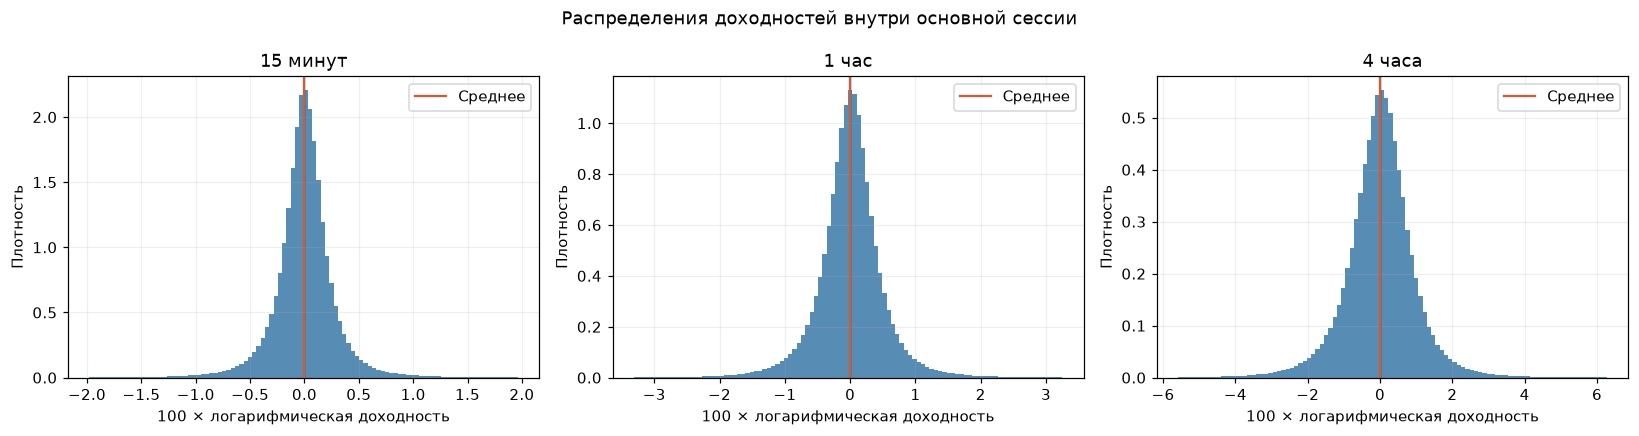

In [3]:
def describe_returns(values):
    values = values.dropna()
    return pd.Series({
        "n": len(values), "mean": values.mean(), "median": values.median(),
        "std": values.std(), "q01": values.quantile(0.01), "q99": values.quantile(0.99),
        "min": values.min(), "max": values.max(), "skew": values.skew(),
        "excess_kurtosis": values.kurt(), "zero_pct": 100 * values.eq(0).mean(),
        "positive_pct": 100 * values.gt(0).mean(),
    })

horizon_labels = {1: "15 минут", 4: "1 час", 16: "4 часа"}
distribution_summary = pd.DataFrame({
    horizon_labels[h]: describe_returns(100 * session_bars[f"log_return_{h}"])
    for h in horizon_labels
}).T
display(distribution_summary.round(5))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (h, label) in zip(axes, horizon_labels.items()):
    values = 100 * session_bars[f"log_return_{h}"].dropna()
    lo, hi = values.quantile([0.001, 0.999])
    ax.hist(values, bins=100, range=(lo, hi), density=True, color="#3978a8", alpha=0.85)
    ax.axvline(0, color="black", lw=0.8)
    ax.axvline(values.mean(), color="#cf5c36", label="Среднее")
    ax.set(title=label, xlabel="100 × логарифмическая доходность", ylabel="Плотность")
    ax.legend()
fig.suptitle("Распределения доходностей внутри основной сессии")
fig.tight_layout()
plt.show()

# Детализация на всех трёх горизонтах сохраняется в отдельной таблице.
instrument_distribution = pd.DataFrame([
    {"ticker": ticker, "horizon": h, **describe_returns(100 * part[f"log_return_{h}"]).to_dict()}
    for ticker, part in session_bars.groupby("ticker") for h in horizon_labels
])

### 2.2. Средняя доходность по времени суток, дням недели и месяцам года

Сначала усредняем доходность инструментов в каждом дне, затем сравниваем дни. Это равновзвешенное среднее по доступным инструментам; пропущенное значение не заменяется нулём. Число наблюдений `n` ниже — число дней, а не число баров или акций.

Полосы показывают ориентировочный интервал `mean ± 1.96 × std / sqrt(n)` по дневным наблюдениям. Он не учитывает временную зависимость и множественные сравнения: графики служат для EDA, а не доказательства сезонности. Последнее часовое окно длится 30 минут, остальные — 60; укороченные окна праздничных сессий исключены из почасового сравнения.

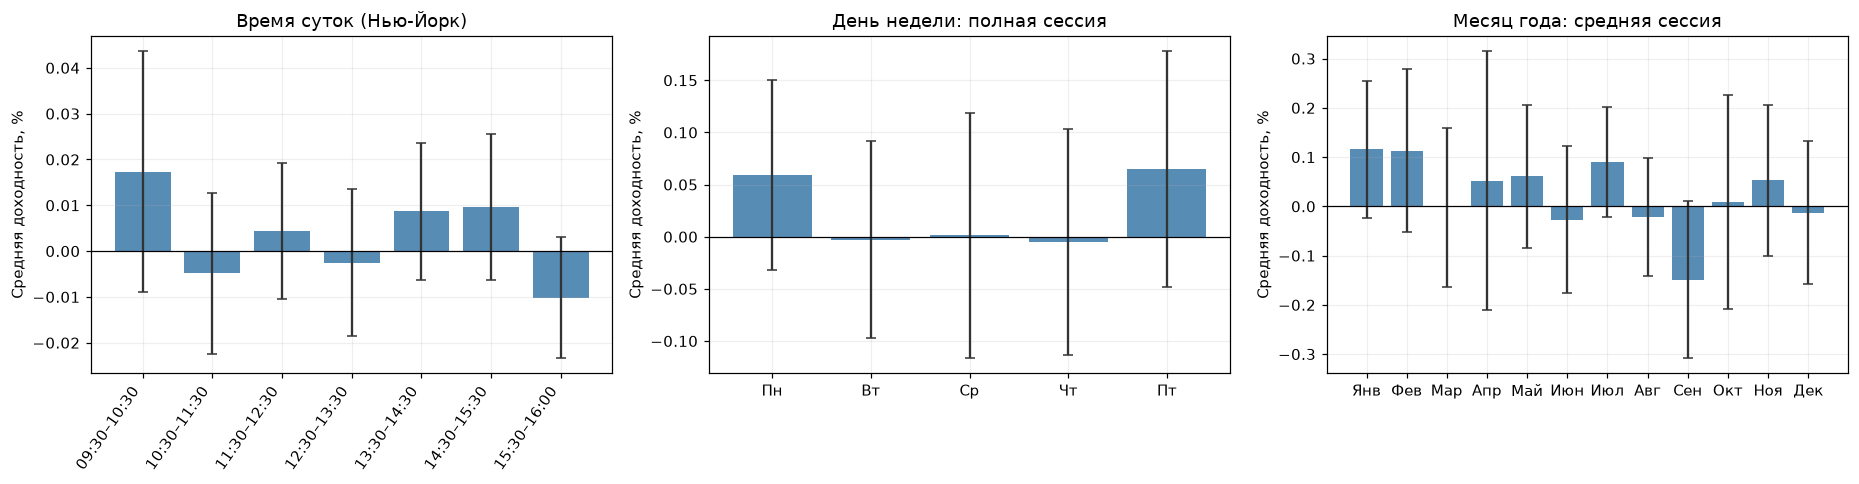

**Время суток**

,n,mean,median,std,ci95_approx
09:30–10:30,1223,0.01738,0.02929,0.46742,0.02620
10:30–11:30,1223,-0.00479,0.00179,0.31367,0.01758
11:30–12:30,1223,0.00443,0.01954,0.26519,0.01486
12:30–13:30,1213,-0.00254,0.01289,0.28596,0.01609
13:30–14:30,1213,0.00874,0.00888,0.26552,0.01494
14:30–15:30,1213,0.00963,0.01555,0.28435,0.01600
15:30–16:00,1213,-0.01016,-0.00284,0.23390,0.01316


**Дни недели**

,n,mean,median,std,ci95_approx
Пн,228,0.05928,0.09875,0.70124,0.09102
Вт,254,-0.00279,0.10031,0.77071,0.09478
Ср,252,0.00127,0.00380,0.95159,0.11749
Чт,244,-0.00500,-0.03282,0.86028,0.10795
Пт,245,0.06456,0.11605,0.90258,0.11302


**Месяцы года**

,n,mean,median,std,ci95_approx
Янв,101,0.11606,0.10028,0.71423,0.13929
Фев,96,0.11277,0.18646,0.82632,0.16530
Мар,109,-0.00163,-0.00093,0.85939,0.16134
Апр,103,0.05196,0.19097,1.35925,0.26250
Май,106,0.06109,0.03112,0.76275,0.14521
Июн,102,-0.02712,0.06005,0.77093,0.14961
Июл,106,0.09095,0.12756,0.58672,0.11170
Авг,110,-0.02110,-0.00831,0.63996,0.11959
Сен,103,-0.14881,0.01404,0.82291,0.15892
Окт,89,0.00911,0.02954,1.04318,0.21673


In [4]:
weekday_labels = ["Пн", "Вт", "Ср", "Чт", "Пт"]
month_labels = ["Янв", "Фев", "Мар", "Апр", "Май", "Июн", "Июл", "Авг", "Сен", "Окт", "Ноя", "Дек"]
hour_labels = ["09:30–10:30", "10:30–11:30", "11:30–12:30", "12:30–13:30",
               "13:30–14:30", "14:30–15:30", "15:30–16:00"]
market_daily = daily_returns.groupby(["date", "weekday", "month"], as_index=False).agg(
    return_pct=("return_pct", "mean"), instruments=("ticker", "nunique"))
market_hourly = hourly_returns.groupby(["date", "hour_slot"], as_index=False).agg(
    return_pct=("return_pct", "mean"), instruments=("ticker", "nunique"))

def calendar_stats(frame, key, order):
    stats = frame.groupby(key).return_pct.agg(n="count", mean="mean", median="median", std="std")
    stats["ci95_approx"] = 1.96 * stats["std"] / np.sqrt(stats.n)
    return stats.reindex(order)

hour_stats = calendar_stats(market_hourly, "hour_slot", range(7))
weekday_stats = calendar_stats(market_daily, "weekday", range(5))
month_stats = calendar_stats(market_daily, "month", range(1, 13))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, stats, labels, title in [
    (axes[0], hour_stats, hour_labels, "Время суток (Нью-Йорк)"),
    (axes[1], weekday_stats, weekday_labels, "День недели: полная сессия"),
    (axes[2], month_stats, month_labels, "Месяц года: средняя сессия"),
]:
    x = np.arange(len(stats))
    ax.bar(x, stats["mean"], color="#3978a8", alpha=0.85)
    ax.errorbar(x, stats["mean"], yerr=stats.ci95_approx, fmt="none", color="#333333", capsize=3)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xticks(x, labels, rotation=55 if ax is axes[0] else 0, ha="right" if ax is axes[0] else "center")
    ax.set(title=title, ylabel="Средняя доходность, %")
fig.tight_layout()
plt.show()
for title, stats, labels in [("Время суток", hour_stats, hour_labels),
                            ("Дни недели", weekday_stats, weekday_labels),
                            ("Месяцы года", month_stats, month_labels)]:
    display(Markdown(f"**{title}**"))
    display(stats.set_axis(labels).round(5))

### 2.3. Детализация по инструментам

Тепловые карты показывают среднюю обычную доходность в процентах. Для времени суток используется доходность соответствующего окна; для дней недели и месяцев года — доходность всей сессии. У каждой карты своя симметричная цветовая шкала. На гистограммах отдельно показаны 15-минутные доходности каждого инструмента; оси общие, хвосты ограничены только при отображении.

,n,mean,median,std,q01,q99,min,max,skew,excess_kurtosis,zero_pct,positive_pct
ticker,,,,,,,,,,,,
AEP,1223.0,-0.00692,0.03925,1.17399,-3.08045,2.70006,-5.92863,4.90099,-0.30765,1.60884,0.24530,51.59444
APP,1223.0,0.05589,0.05997,3.82728,-9.22187,9.73475,-18.78280,17.12262,0.00216,1.93391,0.16353,50.69501
AXP,1223.0,0.01716,0.03055,1.52533,-4.04323,3.77060,-8.57348,15.51815,0.56016,10.62695,0.00000,51.59444
BAC,1223.0,0.00620,0.02772,1.37802,-3.78479,3.41000,-5.40499,9.16299,0.14745,3.03115,0.65413,50.77678
BRK.B,1223.0,-0.00480,0.01928,0.95714,-2.38193,2.27593,-4.87091,6.27959,0.26705,3.83818,0.08177,51.18561
C,1223.0,0.05614,0.10917,1.53981,-3.96719,3.89133,-6.11236,12.98450,0.42283,5.12685,0.32706,53.14800
CMCSA,1223.0,-0.03656,0.02393,1.59333,-4.06674,4.15118,-11.07881,8.12308,-0.52001,6.19815,0.40883,50.12265
D,1223.0,-0.03255,0.00000,1.30685,-3.48214,2.92064,-7.47631,6.09384,-0.30487,2.24469,0.57236,49.71382
DIS,1223.0,0.01259,0.02067,1.44347,-3.60260,3.16343,-6.50627,12.42465,0.36467,5.33185,0.16353,50.36795


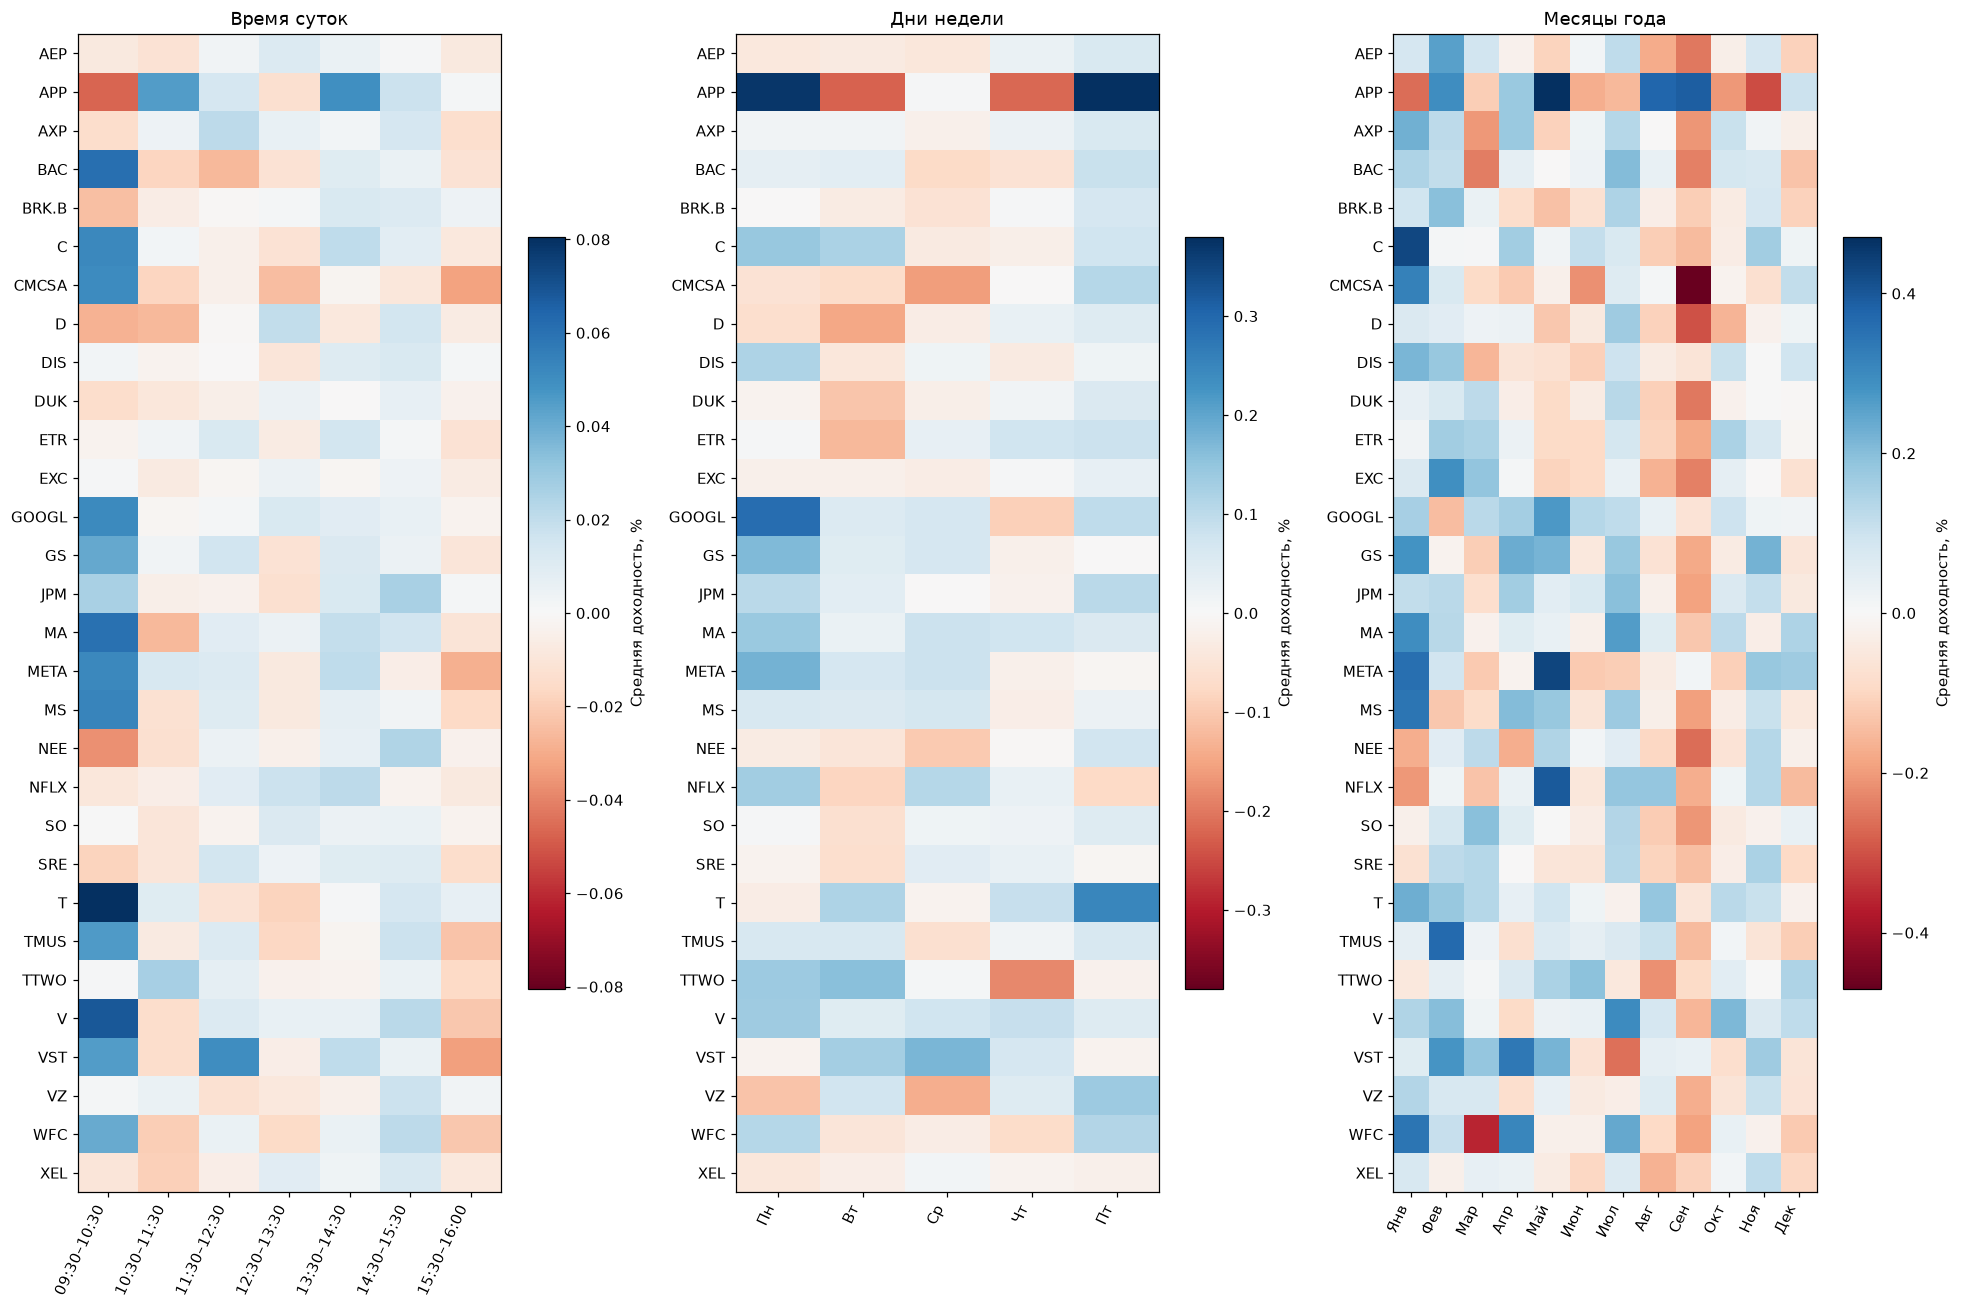

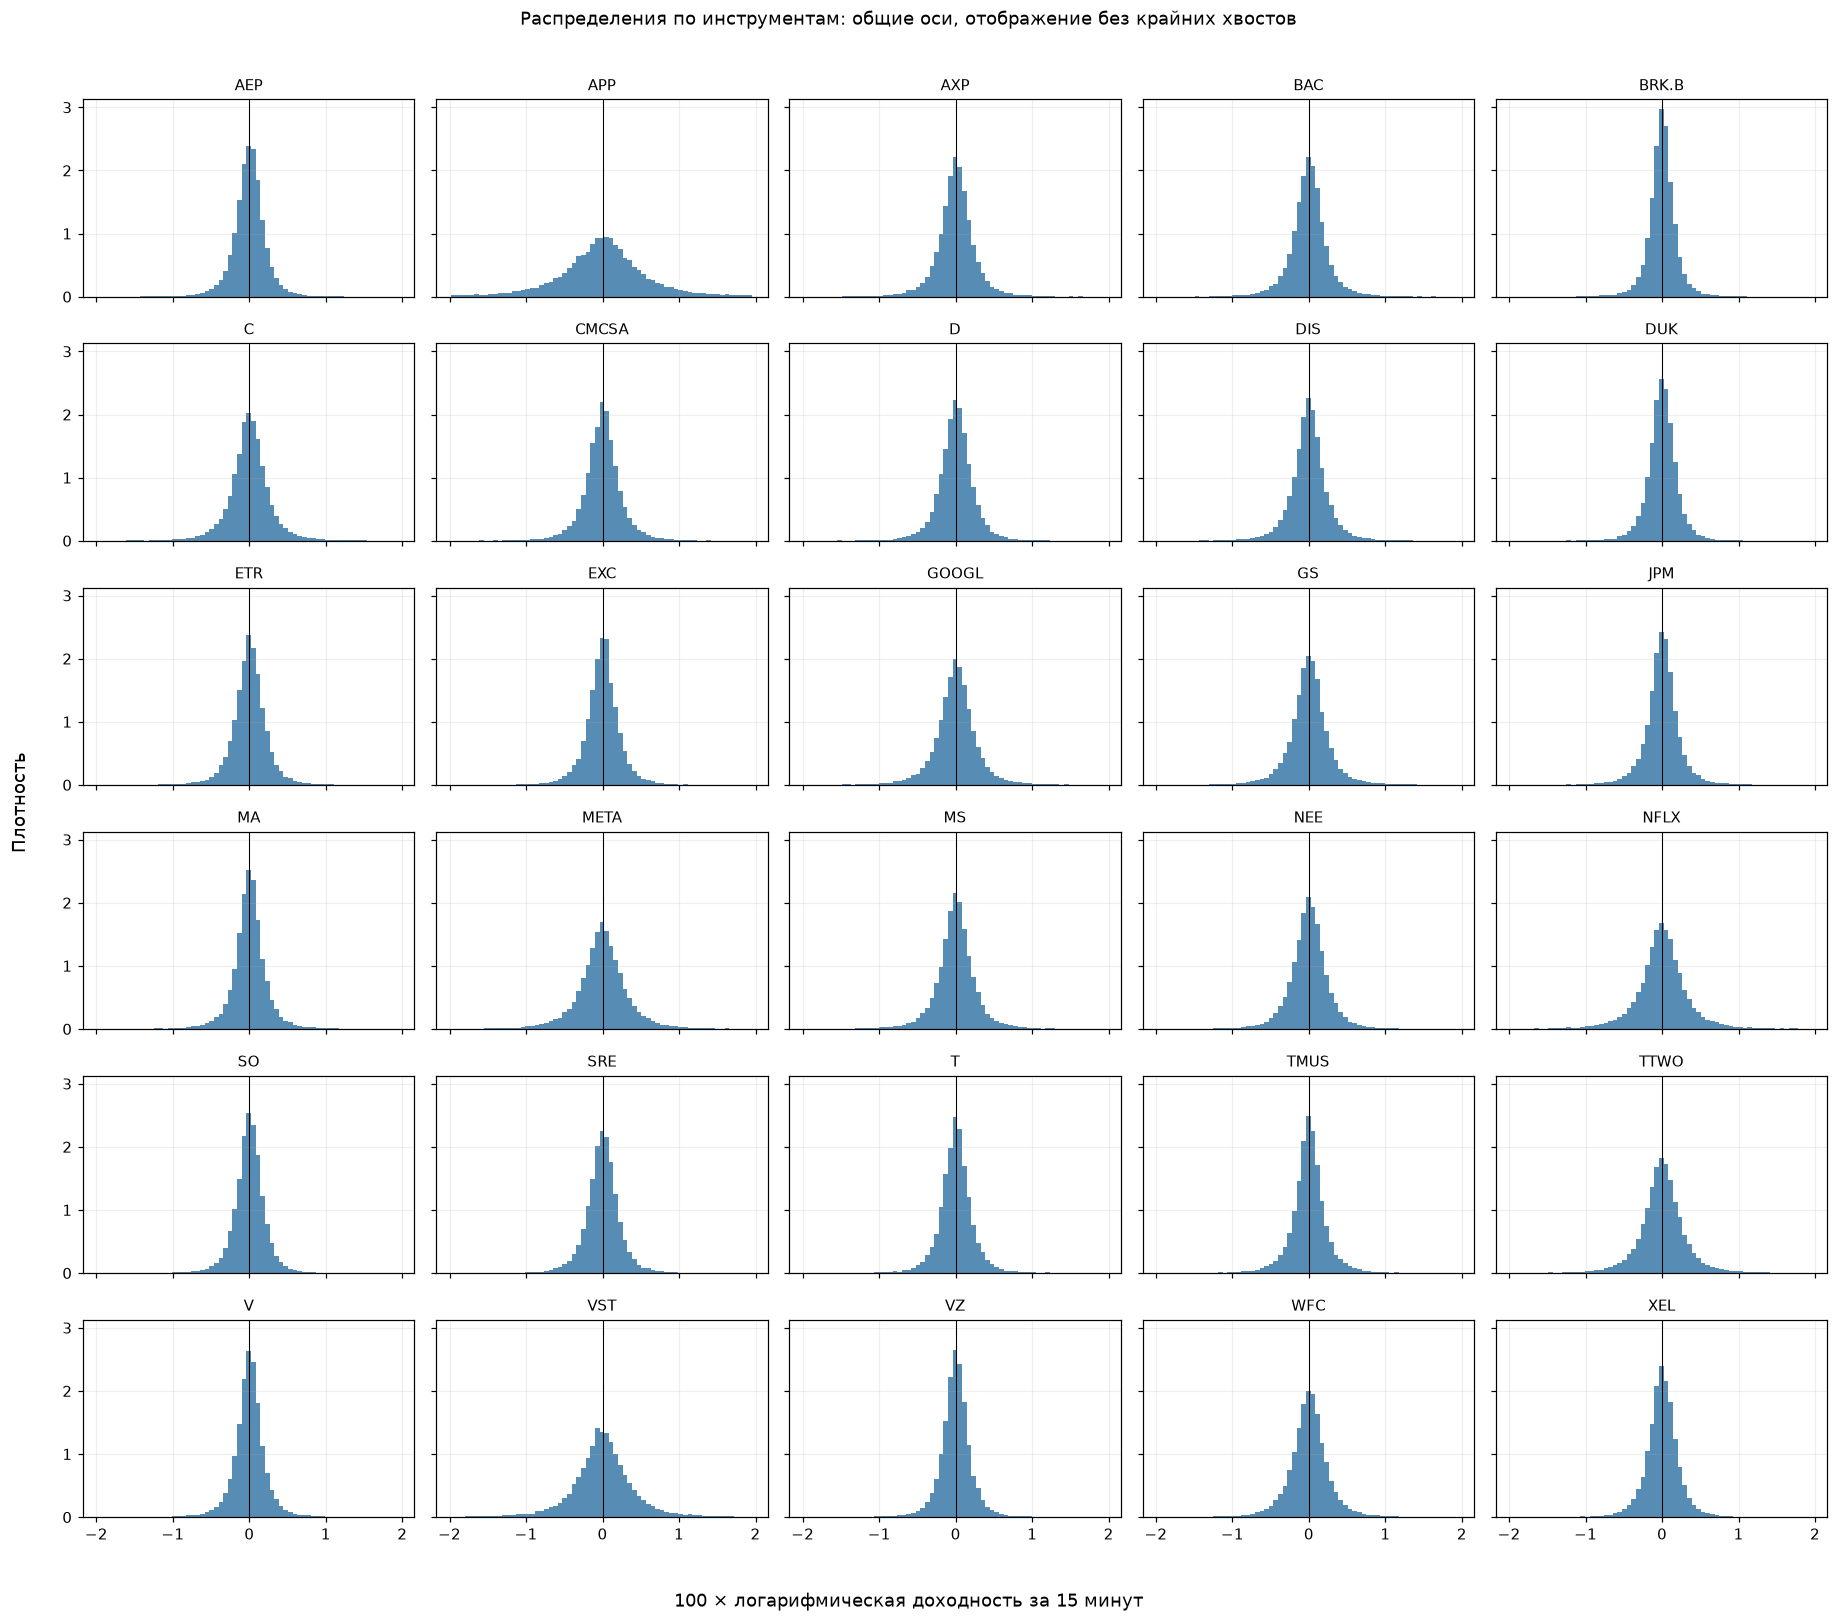

In [5]:
instrument_daily_summary = pd.DataFrame([
    {"ticker": ticker, **describe_returns(part.return_pct).to_dict()}
    for ticker, part in daily_returns.groupby("ticker")
]).set_index("ticker")
with pd.option_context("display.max_rows", 40, "display.max_columns", None):
    display(instrument_daily_summary.round(5))

instrument_hour = hourly_returns.pivot_table(index="ticker", columns="hour_slot", values="return_pct", aggfunc="mean").reindex(columns=range(7))
instrument_weekday = daily_returns.pivot_table(index="ticker", columns="weekday", values="return_pct", aggfunc="mean").reindex(columns=range(5))
instrument_month = daily_returns.pivot_table(index="ticker", columns="month", values="return_pct", aggfunc="mean").reindex(columns=range(1, 13))
fig, axes = plt.subplots(1, 3, figsize=(18, 12))
for ax, table, labels, title in [
    (axes[0], instrument_hour, hour_labels, "Время суток"),
    (axes[1], instrument_weekday, weekday_labels, "Дни недели"),
    (axes[2], instrument_month, month_labels, "Месяцы года"),
]:
    limit = np.nanmax(np.abs(table.to_numpy())) or 1
    im = ax.imshow(table, cmap="RdBu", vmin=-limit, vmax=limit, aspect="auto")
    ax.set_yticks(range(len(table)), table.index)
    ax.set_xticks(range(len(labels)), labels, rotation=65, ha="right")
    ax.set_title(title)
    ax.grid(False)
    fig.colorbar(im, ax=ax, shrink=0.65, label="Средняя доходность, %")
fig.tight_layout()
plt.show()

tickers = sorted(session_bars.ticker.unique())
fig, axes = plt.subplots(int(np.ceil(len(tickers) / 5)), 5, figsize=(17, 15), sharex=True, sharey=True)
all_returns = 100 * session_bars.log_return_1
lo, hi = all_returns.quantile([0.001, 0.999])
for ax, ticker in zip(axes.flat, tickers):
    values = 100 * session_bars.loc[session_bars.ticker.eq(ticker), "log_return_1"]
    ax.hist(values, bins=65, range=(lo, hi), density=True, color="#3978a8", alpha=0.85)
    ax.axvline(0, color="black", lw=0.7)
    ax.set_title(ticker, fontsize=10)
for ax in axes.flat[len(tickers):]:
    ax.set_visible(False)
fig.supxlabel("100 × логарифмическая доходность за 15 минут")
fig.supylabel("Плотность")
fig.suptitle("Распределения по инструментам: общие оси, отображение без крайних хвостов")
fig.tight_layout(rect=[0.02, 0.02, 1, 0.97])
plt.show()

### 2.4. Календарные месяцы и устойчивость по годам

По каждому инструменту складываем логарифмические доходности сессий внутри календарного месяца и преобразуем обратно: `100 × (exp(sum(log_return)) − 1)`. Это накопленное изменение **только за основные сессии**, без ночей, комиссий и проскальзывания. Месяц включаем, только если у инструмента есть все сессии календаря в пределах периода исследования. Ноябрь 2021 и сентябрь 2026 являются границами выборки; первый месяц неполный.

Для общей линии берём среднее накопленных доходностей инструментов с одинаковым весом. Отдельная карта «год × месяц» позволяет увидеть, повторяется ли наблюдение в разные годы. Неполные календарные месяцы помечаем и исключаем из этой карты.

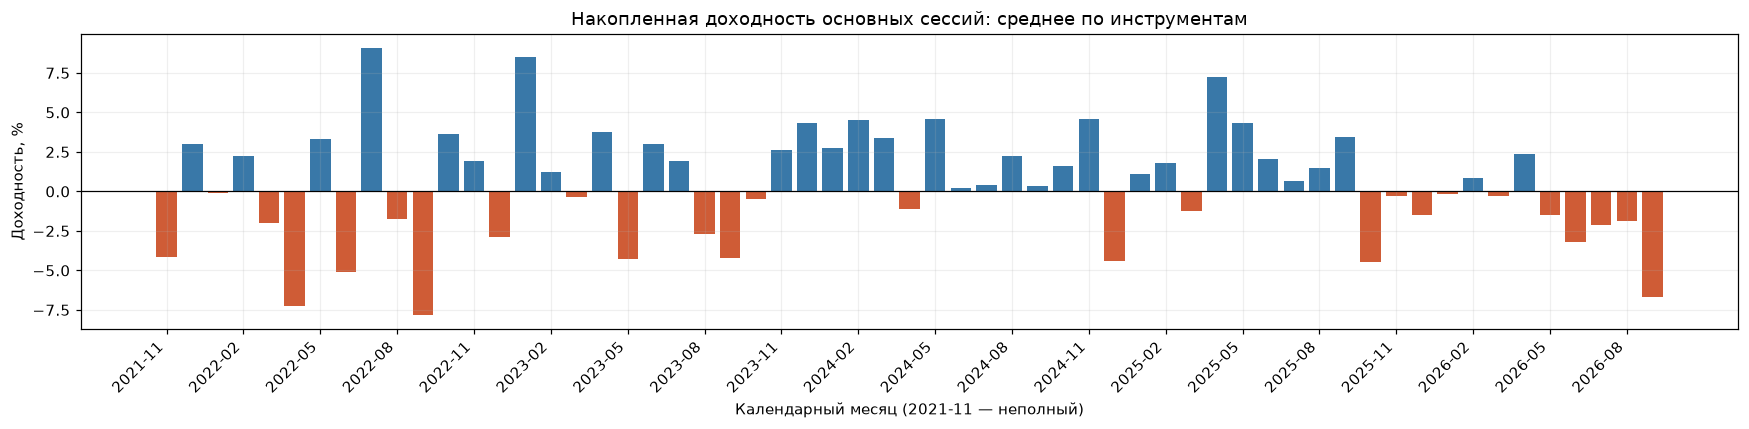

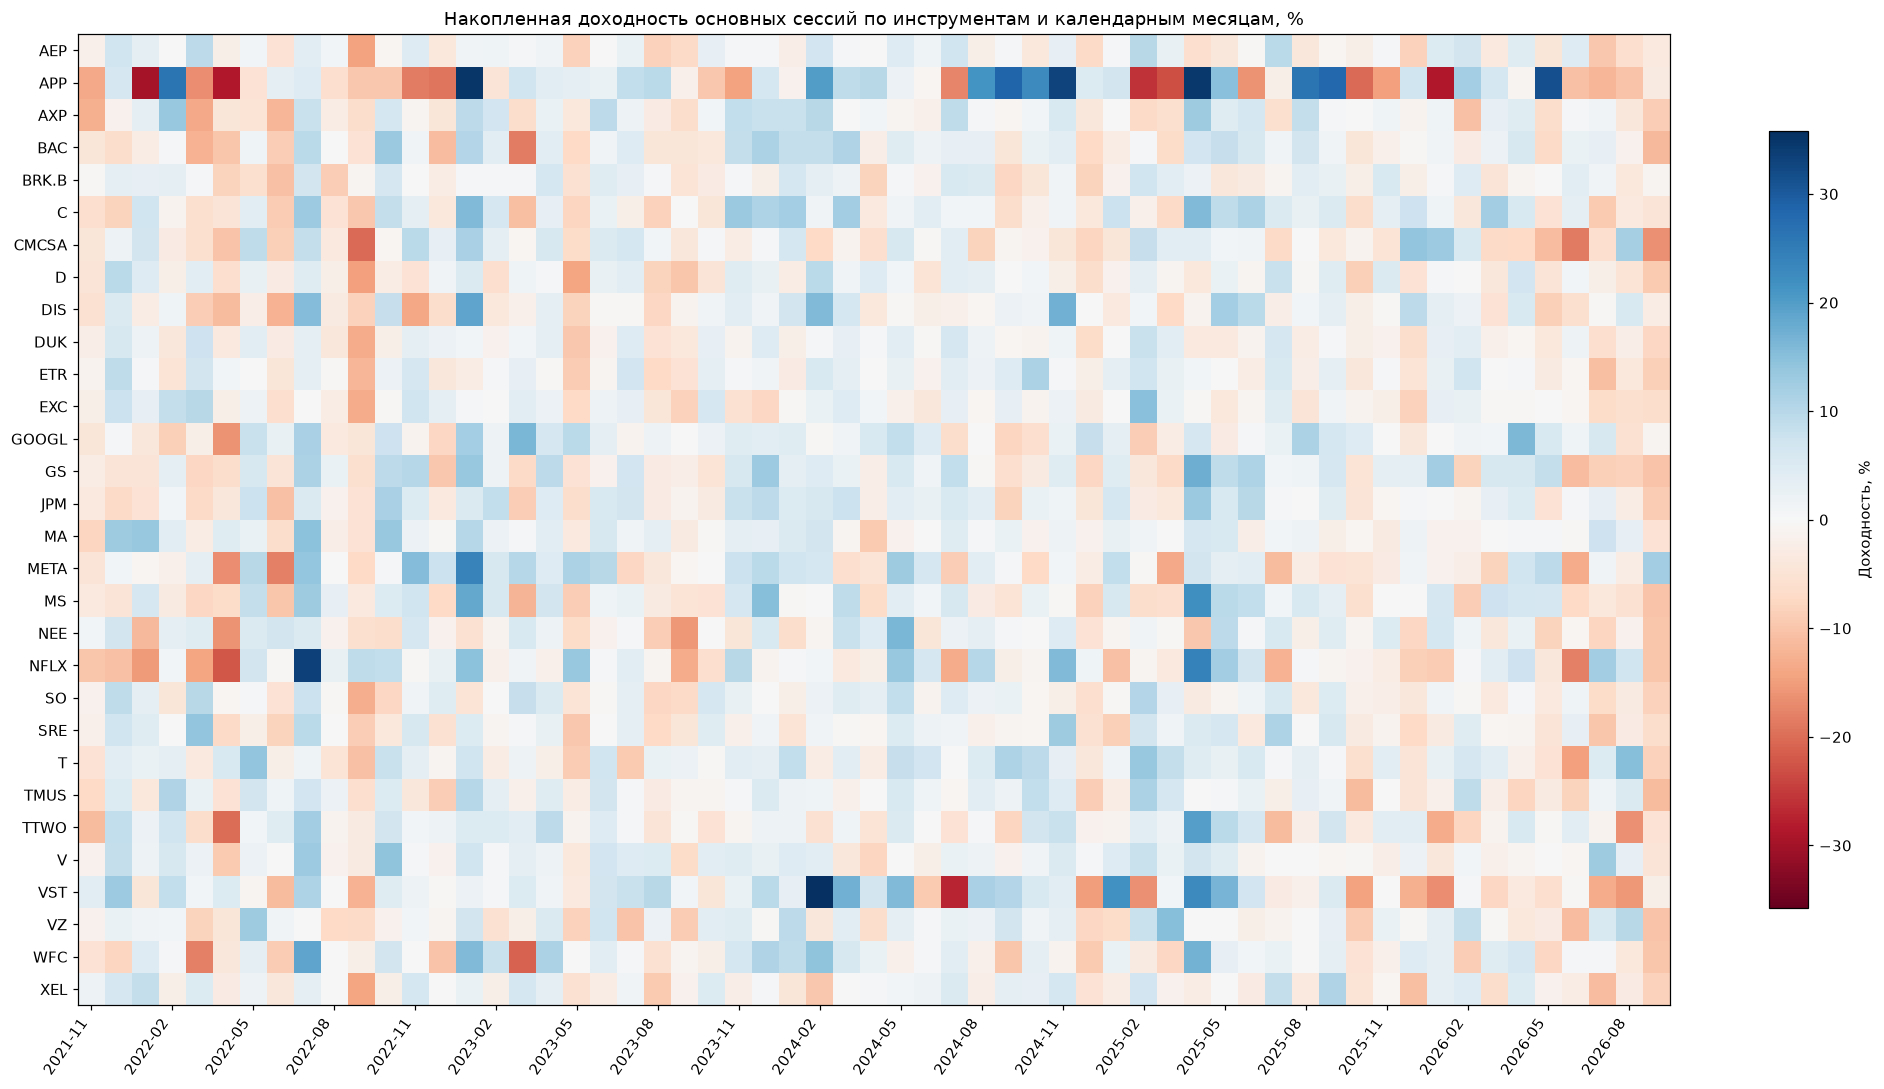

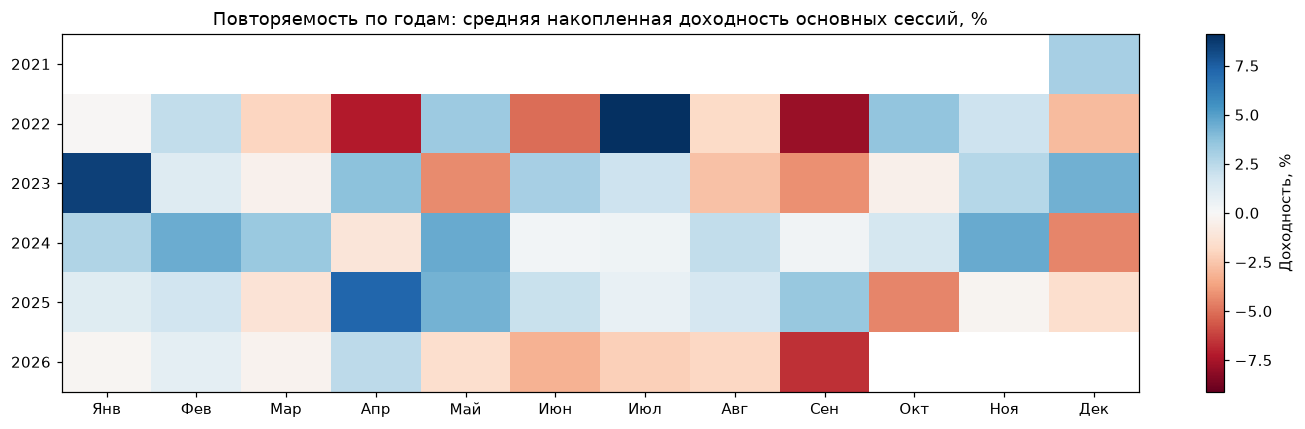

,ticker,year_month,log_return,sessions,expected_sessions,return_pct,partial_month
0,AEP,2021-11,-0.0192,11,11,-1.9022,True
1,AEP,2021-12,0.0701,22,22,7.2610,False
2,AEP,2022-01,0.0322,20,20,3.2701,False
3,AEP,2022-02,-0.0023,19,19,-0.2250,False
4,AEP,2022-03,0.0884,23,23,9.2455,False
5,AEP,2022-04,-0.0202,20,20,-2.0002,False
6,AEP,2022-05,0.0102,21,21,1.0273,False
7,AEP,2022-06,-0.0527,21,21,-5.1334,False
8,AEP,2022-07,0.0385,20,20,3.9262,False
9,AEP,2022-08,0.0104,23,23,1.0421,False


**Таблицы для дальнейшего анализа:** `distribution_summary`, `instrument_distribution`, `daily_returns`, `hourly_returns`, `instrument_daily_summary`, `hour_stats`, `weekday_stats`, `month_stats`, `instrument_hour`, `instrument_weekday`, `instrument_month`, `monthly_returns`, `instrument_monthly`. Календарные закономерности требуют проверки на следующем временном отрезке; экстремальные движения здесь не удаляются.

In [6]:
monthly_returns = daily_returns.groupby(["ticker", "year_month"], as_index=False).agg(
    log_return=("log_return", "sum"), sessions=("date", "nunique"))
schedule_months = pd.to_datetime(return_schedule.index).to_period("M").astype(str)
expected_sessions = pd.Series(schedule_months).value_counts()
monthly_returns["expected_sessions"] = monthly_returns.year_month.map(expected_sessions)
monthly_returns = monthly_returns.loc[monthly_returns.sessions.eq(monthly_returns.expected_sessions)].copy()
monthly_returns["return_pct"] = 100 * np.expm1(monthly_returns.log_return)
# Проверяем полноту календарного месяца независимо от ограниченного периода исследования.
full_schedule = mcal.get_calendar("NYSE").schedule("2021-11-01", "2026-09-30")
full_month_counts = pd.Series(full_schedule.index.to_period("M").astype(str)).value_counts()
monthly_returns["partial_month"] = monthly_returns.expected_sessions.ne(monthly_returns.year_month.map(full_month_counts))
instrument_monthly = monthly_returns.pivot(index="ticker", columns="year_month", values="return_pct")
market_monthly = monthly_returns.groupby("year_month").return_pct.mean()
fig, ax = plt.subplots(figsize=(16, 4))
x = np.arange(len(market_monthly))
ax.bar(x, market_monthly, color=np.where(market_monthly.ge(0), "#3978a8", "#cf5c36"))
ax.set_xticks(x[::3], market_monthly.index[::3], rotation=45, ha="right")
ax.set(title="Накопленная доходность основных сессий: среднее по инструментам",
       ylabel="Доходность, %", xlabel="Календарный месяц (2021-11 — неполный)")
ax.axhline(0, color="black", lw=0.8)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(19, 10))
limit = np.nanmax(np.abs(instrument_monthly.to_numpy())) or 1
im = ax.imshow(instrument_monthly, cmap="RdBu", vmin=-limit, vmax=limit, aspect="auto")
ax.set_yticks(range(len(instrument_monthly)), instrument_monthly.index)
ax.set_xticks(range(0, len(instrument_monthly.columns), 3), instrument_monthly.columns[::3], rotation=55, ha="right")
ax.set_title("Накопленная доходность основных сессий по инструментам и календарным месяцам, %")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="Доходность, %")
fig.tight_layout()
plt.show()

month_year = monthly_returns.loc[~monthly_returns.partial_month].copy()
month_year["year"] = pd.to_datetime(month_year.year_month).dt.year
month_year["month"] = pd.to_datetime(month_year.year_month).dt.month
seasonality_by_year = month_year.pivot_table(index="year", columns="month", values="return_pct", aggfunc="mean").reindex(columns=range(1, 13))
fig, ax = plt.subplots(figsize=(13, 4))
limit = np.nanmax(np.abs(seasonality_by_year.to_numpy())) or 1
im = ax.imshow(seasonality_by_year, cmap="RdBu", vmin=-limit, vmax=limit, aspect="auto")
ax.set_yticks(range(len(seasonality_by_year)), seasonality_by_year.index)
ax.set_xticks(range(12), month_labels)
ax.set_title("Повторяемость по годам: средняя накопленная доходность основных сессий, %")
ax.grid(False)
fig.colorbar(im, ax=ax, label="Доходность, %")
fig.tight_layout()
plt.show()
display(monthly_returns.head(12).round(4))
display(Markdown(
    "**Таблицы для дальнейшего анализа:** `distribution_summary`, `instrument_distribution`, "
    "`daily_returns`, `hourly_returns`, `instrument_daily_summary`, `hour_stats`, "
    "`weekday_stats`, `month_stats`, `instrument_hour`, `instrument_weekday`, "
    "`instrument_month`, `monthly_returns`, `instrument_monthly`. "
    "Календарные закономерности требуют проверки на следующем временном отрезке; "
    "экстремальные движения здесь не удаляются."
))

### Первичные наблюдения

- Анализ охватил 950 340 баров и 36 690 полных инструмент-сессий. На 15-минутном таймфрейме неполных основных сессий не обнаружено.
- Распределения имеют выраженные тяжёлые хвосты: эксцесс 15-минутной логарифмической доходности около 43,76. Медиана равна нулю, доля точно нулевых изменений — около 1,43%. Нормальность распределения предполагать нельзя.
- Стандартное отклонение `100 × log_return` растёт с горизонтом: около 0,316 на 15 минутах, 0,563 на часе и 1,051 на четырёх часах. Это разные горизонты, поэтому сравнивать только их средние без учёта риска недостаточно.
- Разброс равновзвешенной доходности первого часового окна выше, чем у остальных полных часовых окон. Последнее окно длится лишь 30 минут и требует отдельной интерпретации.
- В общей сводке ориентировочные интервалы среднего по каждому часу, дню недели и месяцу года пересекают ноль. Убедительных оснований объявлять найденную календарную закономерность по этим графикам нет.
- Детализация показывает неоднородность инструментов: общая сводка может скрывать противоположные средние изменения. Для будущих моделей полезно проверить прошлые доходности нескольких горизонтов и календарные признаки на отложенном временном периоде.
